In [1]:
import re
import string
import nltk
import mlflow
import dagshub
import mlflow.sklearn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

c:\Users\gupta\OneDrive\Desktop\MLOPS\emotion-detection-mlops\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\gupta\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\gupta\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\gupta\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [3]:
df = pd.read_csv(
    "https://raw.githubusercontent.com/campusx-official/jupyter-masterclass/main/tweet_emotions.csv"
)

df = df.drop(columns=["tweet_id"])

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (40000, 2)


,sentiment,content
0,empty,@tiffanylue i know i was listenin to bad habi...
1,sadness,Layin n bed with a headache ughhhh...waitin o...
2,sadness,Funeral ceremony...gloomy friday...
3,enthusiasm,wants to hang out with friends SOON!
4,neutral,@dannycastillo We want to trade with someone w...


In [4]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nEmotion distribution:")
print(df["sentiment"].value_counts())

Missing values:
sentiment    0
content      0
dtype: int64

Duplicate rows: 91

Emotion distribution:
sentiment
neutral       8638
worry         8459
happiness     5209
sadness       5165
love          3842
surprise      2187
fun           1776
relief        1526
hate          1323
empty          827
enthusiasm     759
boredom        179
anger          110
Name: count, dtype: int64


In [5]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def lower_case(text):
    return text.lower()

def removing_urls(text):
    return re.sub(r"https?://\S+|www\.\S+", "", text)

def removing_numbers(text):
    return re.sub(r"\d+", "", text)

def removing_punctuations(text):
    text = re.sub(rf"[{re.escape(string.punctuation)}]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def remove_stop_words(text):
    return " ".join(
        word for word in text.split()
        if word not in stop_words
    )

def lemmatization(text):
    return " ".join(
        lemmatizer.lemmatize(word)
        for word in text.split()
    )

def normalize_text(text):
    text = str(text)
    text = lower_case(text)
    text = removing_urls(text)
    text = removing_numbers(text)
    text = removing_punctuations(text)
    text = remove_stop_words(text)
    text = lemmatization(text)
    return text

df["content"] = df["content"].fillna("").apply(normalize_text)

display(df.head())

,sentiment,content
0,empty,tiffanylue know listenin bad habit earlier sta...
1,sadness,layin n bed headache ughhhh waitin call
2,sadness,funeral ceremony gloomy friday
3,enthusiasm,want hang friend soon
4,neutral,dannycastillo want trade someone houston ticke...


Filtered dataset shape: (10374, 2)
sentiment
1    5209
0    5165
Name: count, dtype: int64


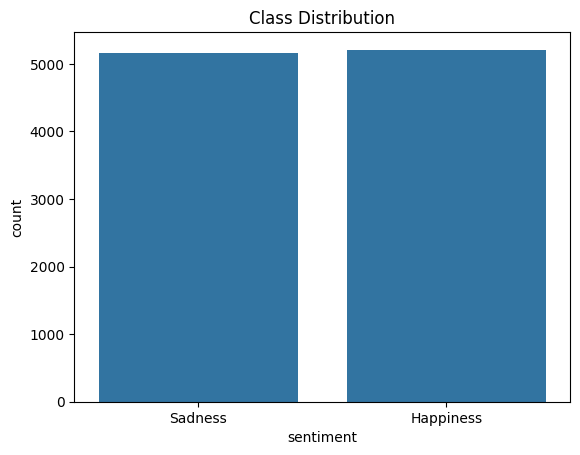

In [6]:
df = df[df["sentiment"].isin(["happiness", "sadness"])].copy()

df["sentiment"] = df["sentiment"].map({
    "sadness": 0,
    "happiness": 1
})

print("Filtered dataset shape:", df.shape)
print(df["sentiment"].value_counts())

sns.countplot(data=df, x="sentiment")
plt.xticks([0, 1], ["Sadness", "Happiness"])
plt.title("Class Distribution")
plt.show()

In [7]:
X = df["content"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8299
Testing samples: 2075


In [8]:
vectorizer = CountVectorizer(max_features=1000)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("Training matrix shape:", X_train_vec.shape)
print("Testing matrix shape:", X_test_vec.shape)

Training matrix shape: (8299, 1000)
Testing matrix shape: (2075, 1000)


In [9]:
dagshub.init(
    repo_owner="Cheeku29",
    repo_name="emotion-detection-mlops",
    mlflow=True
)

mlflow.set_experiment("Emotion Detection - Model Selection")

Accessing as Cheeku29

Initialized MLflow to track repo "Cheeku29/emotion-detection-mlops"

Repository Cheeku29/emotion-detection-mlops initialized!

2026/10/25 19:05:39 INFO mlflow.tracking.fluent: Experiment with name 'Emotion Detection - Model Selection' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/dd8f85caba2a4237a11e2426a8ad63b6', creation_time=1792935340641, effective_trace_archival_retention=None, experiment_id='0', last_update_time=1792935340641, lifecycle_stage='active', name='Emotion Detection - Model Selection', tags={}, trace_location=None, workspace='default'>

In [10]:
print(mlflow.get_tracking_uri())

https://dagshub.com/Cheeku29/emotion-detection-mlops.mlflow


Accuracy: 0.7696385542168674
Precision: 0.7727272727272727
Recall: 0.7667946257197696
F1 Score: 0.7697495183044316

Classification Report:
              precision    recall  f1-score   support

     Sadness       0.77      0.77      0.77      1033
   Happiness       0.77      0.77      0.77      1042

    accuracy                           0.77      2075
   macro avg       0.77      0.77      0.77      2075
weighted avg       0.77      0.77      0.77      2075



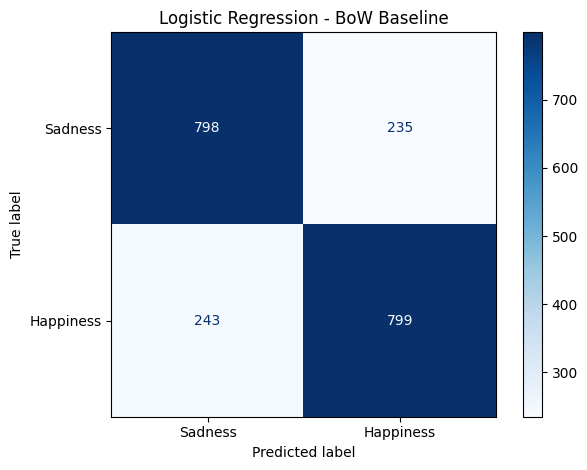

2026/10/25 19:06:39 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/25 19:06:57 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.



Baseline experiment logged to MLflow.
🏃 View run Logistic Regression - BoW Baseline at: https://dagshub.com/Cheeku29/emotion-detection-mlops.mlflow/#/experiments/0/runs/e89deff93b80449887e319d1bb1e8115
🧪 View experiment at: https://dagshub.com/Cheeku29/emotion-detection-mlops.mlflow/#/experiments/0


In [11]:
with mlflow.start_run(run_name="Logistic Regression - BoW Baseline"):

    # Train
    model = LogisticRegression(max_iter=1000)
    model.fit(X_train_vec, y_train)

    # Predict
    y_pred = model.predict(X_test_vec)

    # Evaluate
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1 Score:", f1)

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Sadness", "Happiness"],
            zero_division=0
        )
    )

    # Log parameters
    mlflow.log_params({
        "model": "Logistic Regression",
        "vectorizer": "Bag of Words",
        "max_features": 1000,
        "test_size": 0.2,
        "random_state": 42,
        "max_iter": 1000,
        "preprocessing": "lowercase, URLs, numbers, punctuation, stopwords, lemmatization"
    })

    # Log metrics
    mlflow.log_metrics({
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    })

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Sadness", "Happiness"]
    )

    disp.plot(cmap="Blues")
    plt.title("Logistic Regression - BoW Baseline")
    plt.tight_layout()
    plt.savefig("confusion_matrix_baseline.png", dpi=150)
    plt.show()
    plt.close()

    # Log confusion matrix artifact
    mlflow.log_artifact(
        "confusion_matrix_baseline.png",
        artifact_path="plots"
    )

    # Log trained model
    mlflow.sklearn.log_model(
        model,
        name="baseline_model",
        serialization_format="pickle"
    )

    print("\nBaseline experiment logged to MLflow.")

In [12]:
sample_texts = [
    "I am feeling so happy today",
    "I feel sad and lonely"
]

sample_cleaned = [normalize_text(text) for text in sample_texts]
sample_vectors = vectorizer.transform(sample_cleaned)

predictions = model.predict(sample_vectors)

label_map = {
    0: "Sadness",
    1: "Happiness"
}

for text, prediction in zip(sample_texts, predictions):
    print(f"Text: {text}")
    print(f"Predicted emotion: {label_map[prediction]}\n")

Text: I am feeling so happy today
Predicted emotion: Happiness

Text: I feel sad and lonely
Predicted emotion: Sadness

